# Case Study: Poverty Targeting in Malawi


In [1]:
import sys
print(sys.executable)

/Users/miekochun/miniforge3/bin/python


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rvp import (
    AllocationData,
    AllocationProblem,
    BenefitDimension,
    CapacityDimension,
    CostSurface,
    DataLabelingDimension,
    DesignSpace,
    plot_welfare_surface,
)
from rvp.constraints import CoverageConstraint
from rvp.policies import RankingPolicy
from rvp.utilities import CRRAUtility, PartitionedUtility
from rvp.comparison import optimize_budget_frontier

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 18
plt.rcParams["axes.labelsize"] = 22
plt.rcParams["axes.titlesize"] = 22
plt.rcParams["xtick.labelsize"] = 18
plt.rcParams["ytick.labelsize"] = 18
plt.rcParams["legend.fontsize"] = 16


## Load prediction data


In [3]:
folder_path = Path("data/seed/")

files = sorted(folder_path.glob("seed_*.csv"))

data_list = [pd.read_csv(path) for path in files]
data = AllocationData(df=data_list)


## Allocation Problem


In [4]:
BASE_ALPHA = 0.15
BASE_BENEFIT = 100
RHO = 3.0

policy = RankingPolicy(ascending=True)
utility = CRRAUtility(rho=RHO, b=500)
utility_step = PartitionedUtility(thresholds=[0.33], values=[1, 0], threshold_type='percentile')
constraint = CoverageConstraint(max_coverage=1.0, population_size=data.n)

base_problem = AllocationProblem(
    data=data,
    utility=utility,
    constraint=constraint,
    policy=policy,
)

base_problem_step = AllocationProblem(
    data=data,
    utility=utility_step,
    constraint=constraint,
    policy=policy,
)

base_problem.evaluate()


{'total_utility': 0.0016031584591440703,
 'mean_utility': 5.60740979064033e-07,
 'utility_ratio': 1.0,
 'n_allocated': 2859.0,
 'actions': None}

## Design space


In [5]:
capacity_dim = CapacityDimension(bounds=(0.01, 1.0), name=r"Capacity ($\alpha$)")
benefit_dim = BenefitDimension(bounds=(1, 1000), name=r"Benefit ($b$)")
labeling_dim = DataLabelingDimension(
    base_problem=base_problem,
    bounds=(0.0, 1.0),
    seed=42,
    name="Label Fraction",
    unlabeled_strategy="population_mean"
)

space = DesignSpace(
    base_problem=base_problem,
    dimensions=[capacity_dim, benefit_dim, labeling_dim],
)

space_step = DesignSpace(
    base_problem=base_problem_step,
    dimensions=[capacity_dim, labeling_dim],
)

welfare_norm = space.welfare_at(
    {
        capacity_dim: 1.0,
        benefit_dim: 100,
        labeling_dim: 1.0,
    },
    metric="mean_utility",
)


space


DesignSpace(dimensions=['Capacity ($\\alpha$)', 'Benefit ($b$)', 'Label Fraction'])

# Step-Function Utility


## (Q1) Local Rate of Improvement


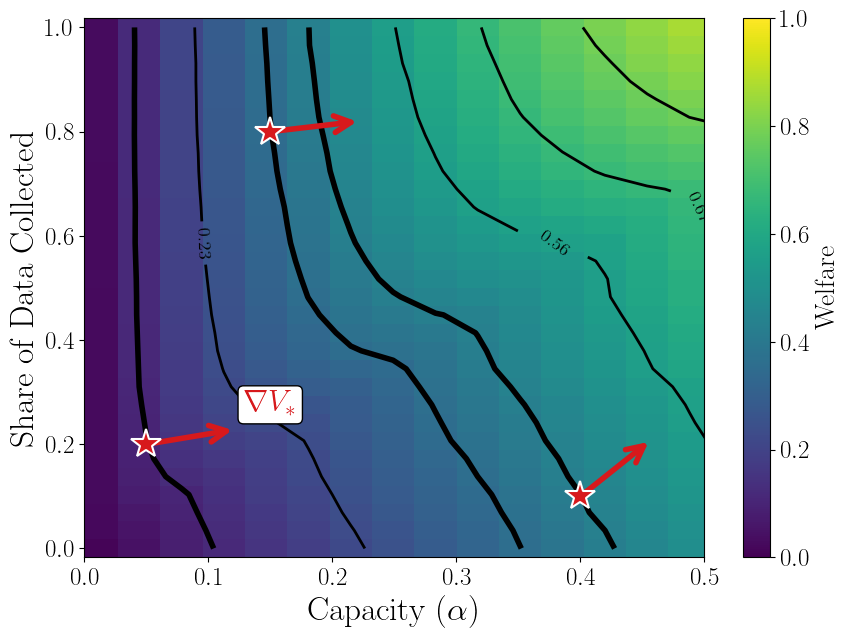

In [6]:
fig, ax = plot_welfare_surface(
    space_step,
    dim_x=capacity_dim,
    dim_y=labeling_dim,
    welfare_metric="mean_utility",
    normalize='max',
    xlim=(0.0, 0.5),
    n=30,
    status_quo=[{capacity_dim: 0.05, labeling_dim: 0.2}, 
                {capacity_dim: 0.4, labeling_dim: 0.1},
                {capacity_dim: 0.15, labeling_dim: 0.8}],
    cmap="viridis",
    n_contours=8,
    cbar_label="Welfare",
)

ax.set_ylabel("Share of Data Collected")
plt.show()


## (Q2) Inspecting Optimality


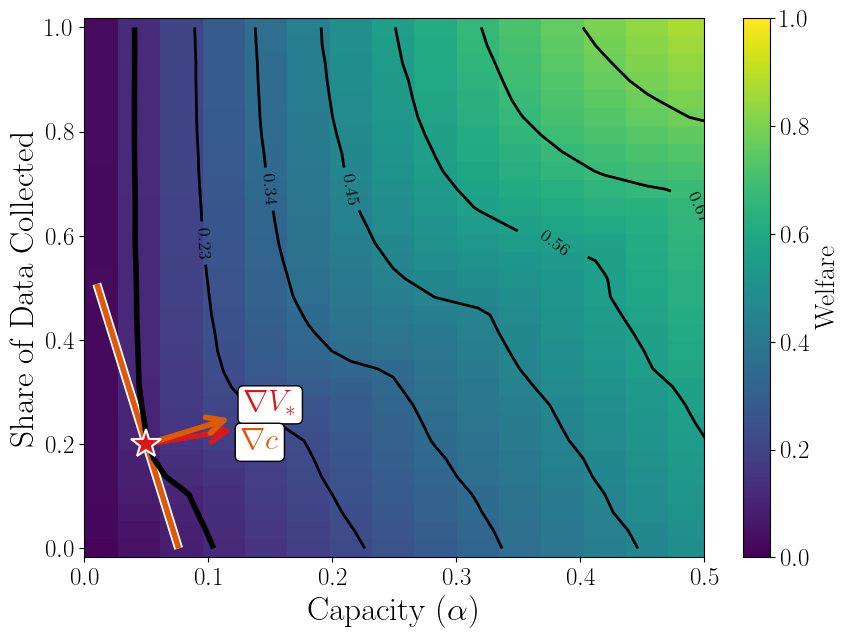

In [7]:
COST_PER_LABEL = 13

cost_surface = CostSurface(
    lambda config: data.n * (
        float(config[capacity_dim]) * float(BASE_BENEFIT)
        + float(config[labeling_dim]) * COST_PER_LABEL
    )
)

fig, ax = plot_welfare_surface(
    space_step,
    dim_x=capacity_dim,
    dim_y=labeling_dim,
    welfare_metric="mean_utility",
    normalize='max',
    xlim=(0.0, 0.5),
    n=30,
    status_quo={capacity_dim: 0.05, labeling_dim: 0.2},
    cmap="viridis",
    cost_surface=cost_surface,
    n_contours=8,
    cbar_label="Welfare",
)

ax.set_ylabel("Share of Data Collected")
plt.show()


## (Q3) Choosing Optimal Parameters


In [8]:
BUDGET_MAX_ADDITIONAL = 100_000
N_BUDGET_POINTS = 15
OPT_GRID_N = (100, 100)

budget_results_step, budget_candidates_step = optimize_budget_frontier(
    space=space_step,
    cost_surface=cost_surface,
    solve_dim=capacity_dim,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL),
    n_budget_points=N_BUDGET_POINTS,
    status_quo={
        capacity_dim: 0.01,
        benefit_dim: 100,
        labeling_dim: 0.01,
    },
    n=OPT_GRID_N,
    welfare_metric="mean_utility",
    return_candidates=True,
)

budget_results_step.head()


,budget,optimal_welfare,optimal_cost,unspent_budget,optimal_Capacity ($\alpha$)_theta,optimal_Label Fraction_theta
0,1000.000000,0.006576,1000.000000,4.547474e-13,0.010858,0.030303
1,8071.428571,0.018258,8071.428571,-9.094947e-13,0.027713,0.090909
2,15142.857143,0.030010,15142.857143,0.000000e+00,0.044569,0.151515
3,22214.285714,0.042637,22214.285714,-3.637979e-12,0.061424,0.212121
4,29285.714286,0.055054,29285.714286,3.637979e-12,0.076966,0.282828


Text(0, 0.5, 'Share of Data Collected')

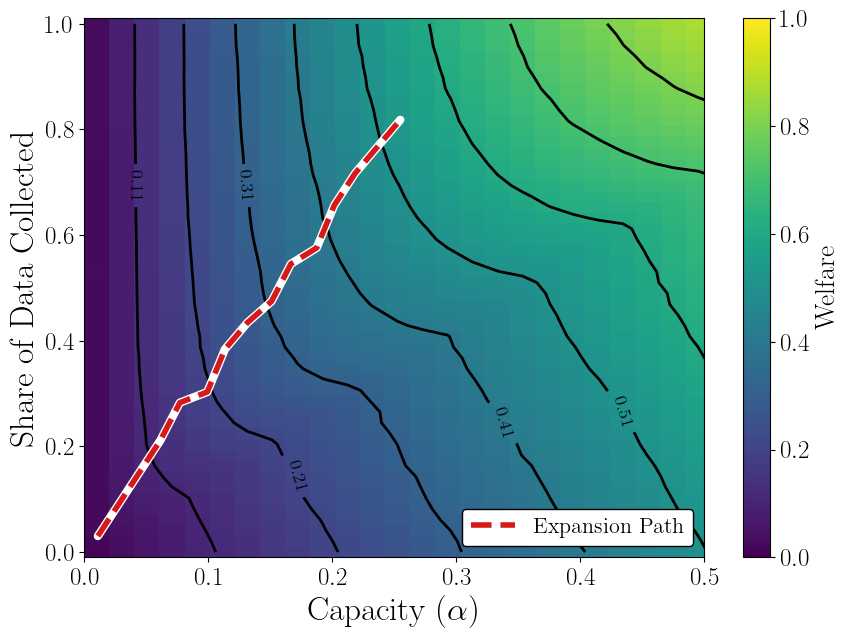

In [9]:
fig, ax = plot_welfare_surface(
    space_step,
    dim_x=capacity_dim,
    dim_y=labeling_dim,
    welfare_metric="mean_utility",
    n=50,
    normalize='max',
    cbar_label='Welfare',
    xlim=(0, 0.5),
    path_results=budget_results_step,
    path_label="Expansion Path"
)
ax.set_ylabel("Share of Data Collected")


# CRRA Utility


## (Q1) Local Rate of Improvement


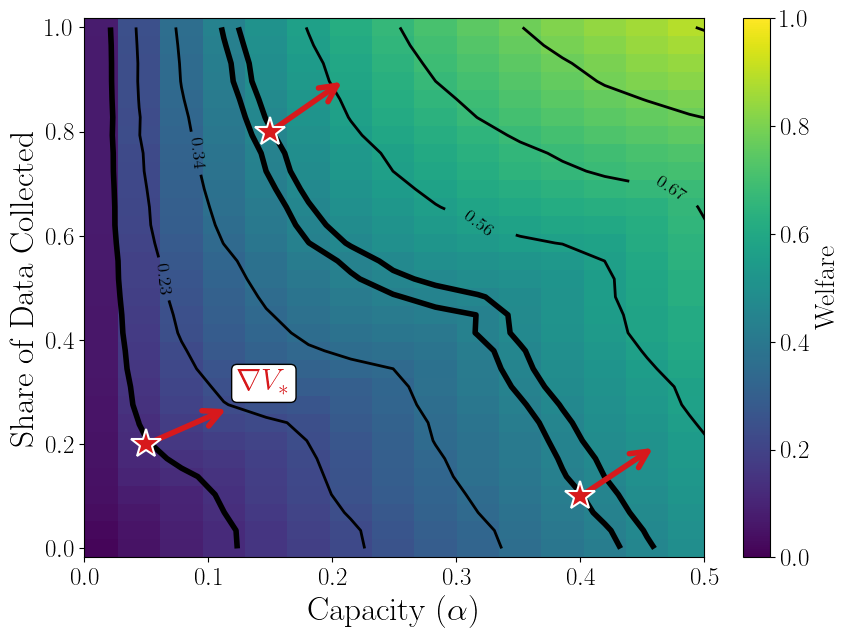

In [10]:
fig, ax = plot_welfare_surface(
    space,
    dim_x=capacity_dim,
    dim_y=labeling_dim,
    fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric="mean_utility",
    normalize_by=welfare_norm,
    n=30,
    xlim=(0.0, 0.5),
    status_quo=[{capacity_dim: 0.05, labeling_dim: 0.2}, 
                {capacity_dim: 0.4, labeling_dim: 0.1},
                {capacity_dim: 0.15, labeling_dim: 0.8}],
    cmap="viridis",
    n_contours=8,
    cbar_label="Welfare",
)

ax.set_ylabel("Share of Data Collected")
plt.show()


## (Q2) Inspecting Optimality


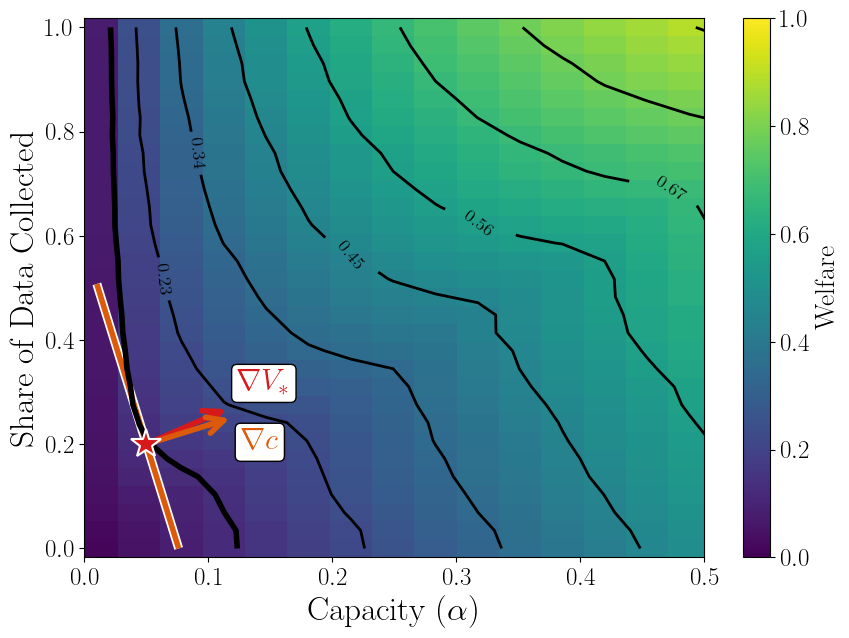

In [11]:
COST_PER_LABEL = 13

cost_surface = CostSurface(
    lambda config: data.n * (
        float(config[capacity_dim]) * float(BASE_BENEFIT)
        + float(config[labeling_dim]) * COST_PER_LABEL
    )
)

fig, ax = plot_welfare_surface(
    space,
    dim_x=capacity_dim,
    dim_y=labeling_dim,
    welfare_metric="mean_utility",
    normalize_by=welfare_norm,
    xlim=(0.0, 0.5),
    fixed={benefit_dim: BASE_BENEFIT},
    n=30,
    status_quo={capacity_dim: 0.05, labeling_dim: 0.2},
    cmap="viridis",
    cost_surface=cost_surface,
    n_contours=8,
    cbar_label="Welfare",
)

ax.set_ylabel("Share of Data Collected")
plt.show()


## (Q3) Choosing Optimal Parameters


In [12]:
BUDGET_MAX_ADDITIONAL = 100_000
N_BUDGET_POINTS = 15
OPT_GRID_N = (100, 100)

budget_results_crra, budget_candidates_crra = optimize_budget_frontier(
    space=space,
    cost_surface=cost_surface,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL),
    solve_dim=capacity_dim,
    n_budget_points=N_BUDGET_POINTS,
    status_quo= {
            capacity_dim: 0.01,
            benefit_dim: 100,
            labeling_dim: 0.01,
        },
    fixed={benefit_dim: BASE_BENEFIT},
    n=100,
    welfare_metric="mean_utility",
    return_candidates=True,
)


Text(0, 0.5, 'Share of Data Collected')

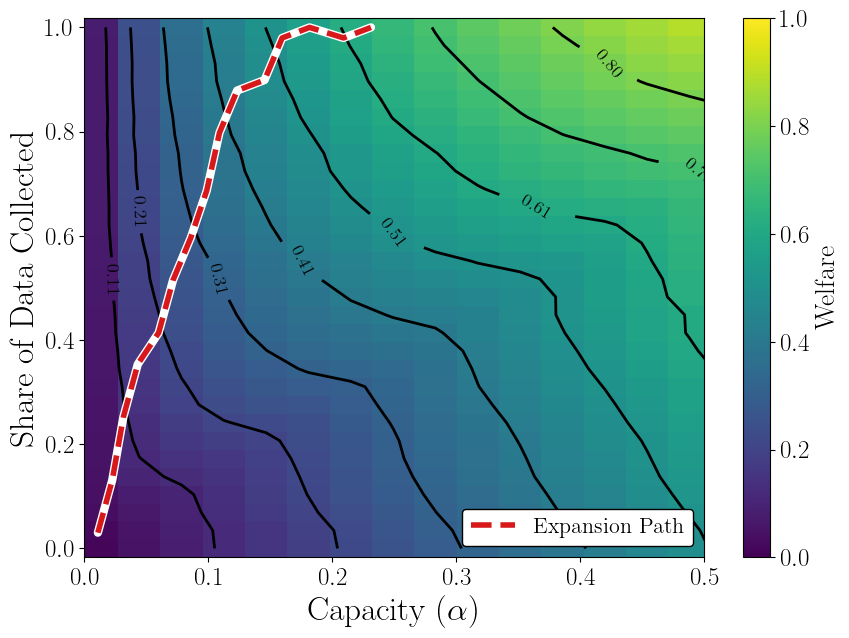

In [13]:
fig, ax = plot_welfare_surface(
    space,
    dim_x=capacity_dim,
    dim_y=labeling_dim,
    fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric="mean_utility",
    n=30,
    normalize='max',
    cbar_label='Welfare',
    xlim=(0, 0.5),
    path_results=budget_results_crra,
    path_label="Expansion Path"
)

ax.set_ylabel("Share of Data Collected")


# Varying Transfer Sizes


In [14]:
capacity_dim = CapacityDimension(bounds=(0.01, 1.0), name=r"Capacity ($\alpha$)")
benefit_dim = BenefitDimension(bounds=(1, 500), name="Cash Transfer (PPP $)")


space = DesignSpace(
    base_problem=base_problem,
    dimensions=[capacity_dim, benefit_dim, labeling_dim],
)

BENEFIT_CAPACITY_WELFARE_SCALE = space.welfare_at(
    {
        capacity_dim: 1.0,
        benefit_dim: 500,
        labeling_dim: 1.0,
    },
    metric="mean_utility",
)

cost_surface_benefit_capacity = CostSurface(
    lambda config: data.n * (
        float(config[capacity_dim]) * float(config[benefit_dim])
    )
)

status_quo_benefit_capacity = {
    capacity_dim: 0.05,
    benefit_dim: 100
}

labeling_dim_fixed = 0.2


## (Q1) Local Improvements


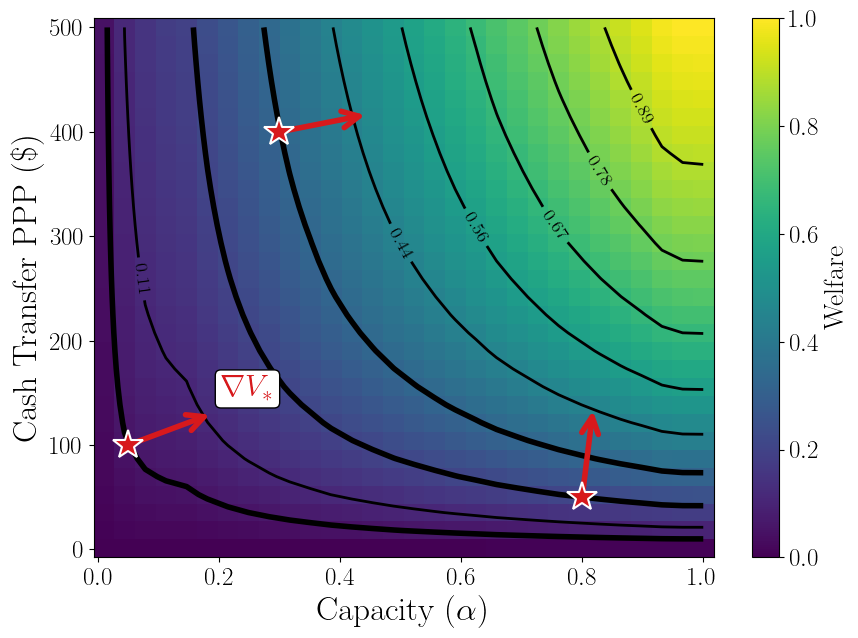

In [15]:
fig, ax = plot_welfare_surface(
    space,
    dim_x=capacity_dim,
    dim_y=benefit_dim,
    status_quo=[status_quo_benefit_capacity, {capacity_dim: 0.8, benefit_dim: 50}, {capacity_dim: 0.3, benefit_dim: 400}],
    fixed={labeling_dim: labeling_dim_fixed},
    welfare_metric="mean_utility",
    normalize_by=BENEFIT_CAPACITY_WELFARE_SCALE,
    n=30,
    n_contours=8,
    cmap="viridis",
    cbar_label="Welfare",
)

ax.set_ylabel(r"Cash Transfer PPP (\$)")
plt.show()


## (Q2) Inspecting Optimality


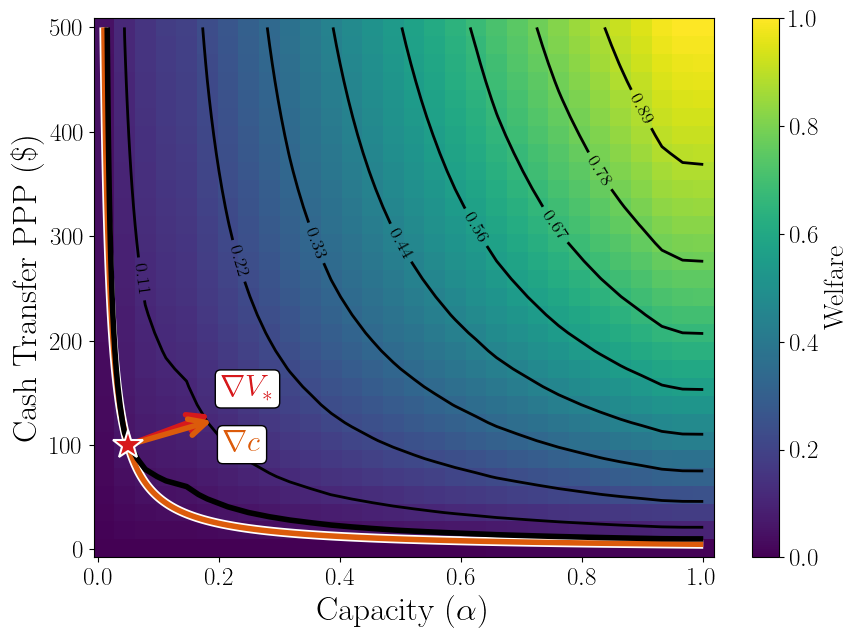

In [16]:
fig, ax = plot_welfare_surface(
    space,
    dim_x=capacity_dim,
    dim_y=benefit_dim,
    status_quo=status_quo_benefit_capacity,
    cost_surface=cost_surface_benefit_capacity,
    fixed={labeling_dim: labeling_dim_fixed},
    welfare_metric="mean_utility",
    normalize_by=BENEFIT_CAPACITY_WELFARE_SCALE,
    n=30,
    n_contours=8,
    cmap="viridis",
    cbar_label="Welfare",
)

ax.set_ylabel(r"Cash Transfer PPP (\$)")
plt.show()


## (Q3) Choosing Optimal Paramters


In [17]:
budgets = np.concatenate([
    np.linspace(1000, 20000, 8),    
    np.linspace(20000, 200000, 8),  
])


benefit_budget_status_quo = {
    capacity_dim: 0.01,
    benefit_dim: 1,
    labeling_dim: labeling_dim_fixed,
}

budget_results_benefit, budget_candidates_benefit = optimize_budget_frontier(
    space=space,
    cost_surface=cost_surface_benefit_capacity,
    solve_dim=capacity_dim,
    budgets=budgets,
    status_quo=benefit_budget_status_quo,
    fixed={labeling_dim: labeling_dim_fixed},
    n=300,
    welfare_metric="mean_utility",
    return_candidates=True,
)


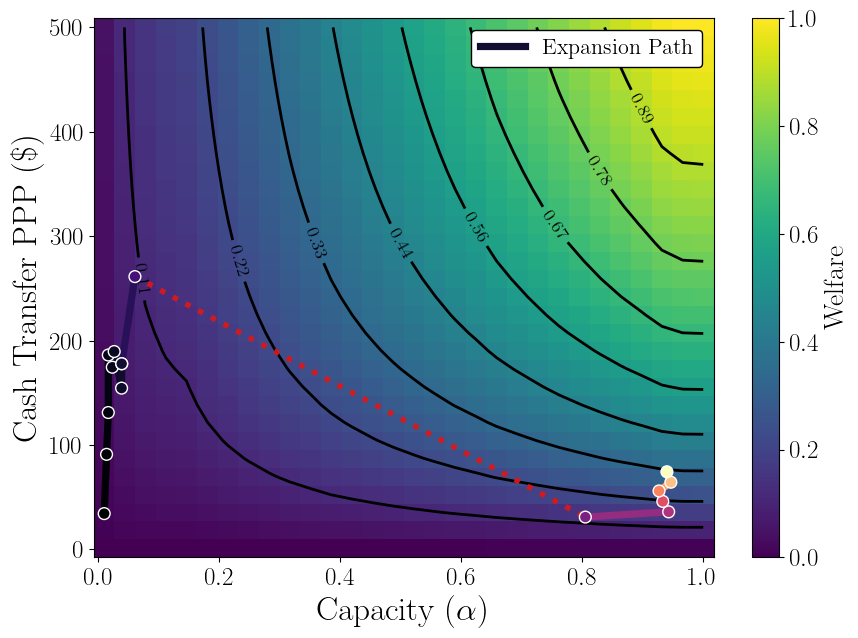

In [18]:
capacity_col = f"optimal_{capacity_dim.name}_theta"
benefit_col = f"optimal_{benefit_dim.name}_theta"
benefit_path_points = (
    budget_results_benefit
    .dropna(subset=["budget", "optimal_welfare", capacity_col, benefit_col])
    .sort_values("budget")
    .reset_index(drop=True)
)

path_xy = benefit_path_points[[capacity_col, benefit_col]].to_numpy(dtype=float)
axis_scale = np.array([
    capacity_dim.bounds[1] - capacity_dim.bounds[0],
    benefit_dim.bounds[1] - benefit_dim.bounds[0],
])
jump_distance = np.linalg.norm(np.diff(path_xy, axis=0) / axis_scale, axis=1)
switch_idx = int(np.nanargmax(jump_distance))
selected_points = benefit_path_points.iloc[
    [max(0, switch_idx - 2), max(0, len(benefit_path_points) - 3)]
]
selected_status_quos = [
    {
        capacity_dim: float(row[capacity_col]),
        benefit_dim: float(row[benefit_col]),
        labeling_dim: labeling_dim_fixed,
    }
    for _, row in selected_points.iterrows()
]

fig, ax = plot_welfare_surface(
    space,
    dim_x=capacity_dim,
    dim_y=benefit_dim,
    fixed={labeling_dim: labeling_dim_fixed},
    welfare_metric="mean_utility",
    n=30,
    normalize_by=BENEFIT_CAPACITY_WELFARE_SCALE,
    cbar_label="Welfare",
    n_contours=8,
    path_results=budget_results_benefit,
    path_label='Expansion Path',
    path_break_threshold=0.18,
    path_bridge_breaks=True,
    path_bridge_color="#d7191c",
    path_bridge_alpha=0.95,
    path_cmap="magma",
    path_linewidth=5.2,
    path_underlay_linewidth=0,
    path_linestyle="-",
    path_marker_size=72,
    path_legend_loc='upper right',
)

ax.set_ylabel(r"Cash Transfer PPP (\$)")
plt.show()


# Joint Optimization: Benefit, Label Fraction, Capacity


In [19]:
COST_PER_LABEL = 13
BUDGET_MAX_ADDITIONAL = 100_000

status_quo = {
    capacity_dim: 0.05,
    benefit_dim: 100,
    labeling_dim: 0.2,
}

cost_surface = CostSurface(
    lambda config: data.n * (
        float(config[capacity_dim]) * float(config[benefit_dim])
        + float(config[labeling_dim]) * COST_PER_LABEL
    )
)


In [20]:
N_BUDGET_POINTS_3D = 30
OPT_GRID_N_3D = {
    capacity_dim: 50,
    labeling_dim: 50,
}

budget_results_benefit_label_capacity, budget_candidates_benefit_label_capacity = optimize_budget_frontier(
    space=space,
    cost_surface=cost_surface,
    solve_dim=benefit_dim,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL),
    n_budget_points=N_BUDGET_POINTS_3D,
    dims=[capacity_dim, benefit_dim, labeling_dim],
    status_quo=status_quo,
    n=OPT_GRID_N_3D,
    welfare_metric="mean_utility",
    return_candidates=True,
)


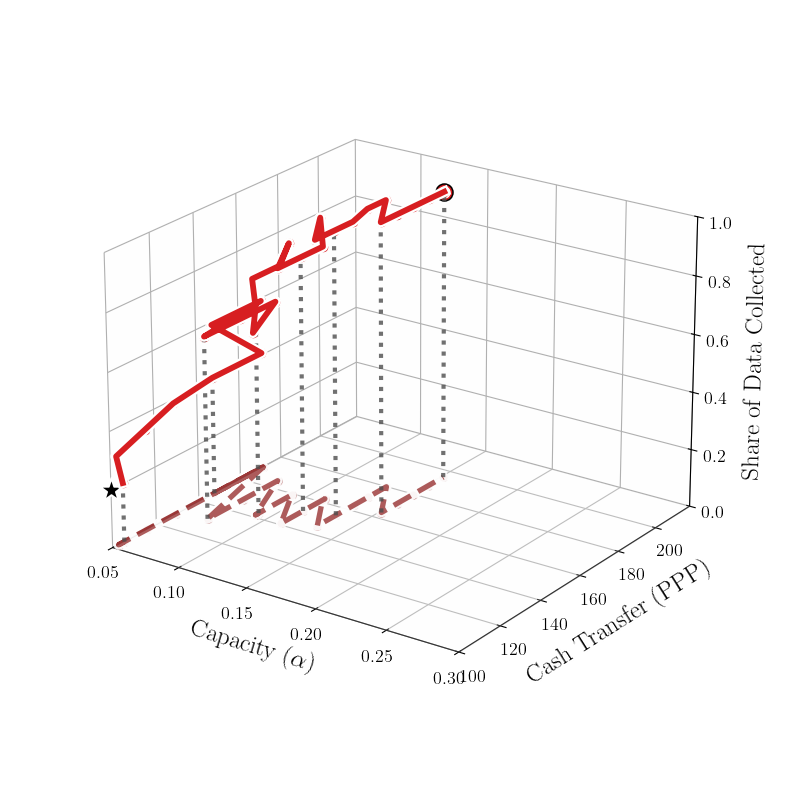

In [21]:
capacity_col = f"optimal_{capacity_dim.name}_theta"
benefit_col = f"optimal_{benefit_dim.name}_theta"
labeling_col = f"optimal_{labeling_dim.name}_theta"

path_3d = (
    budget_results_benefit_label_capacity
    .dropna(subset=["budget", capacity_col, benefit_col, labeling_col])
    .sort_values("budget")
    .reset_index(drop=True)
)
if path_3d.empty:
    raise ValueError("No feasible 3D expansion-path points to plot.")

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

alpha_path = path_3d[capacity_col].to_numpy(dtype=float)
benefit_path = path_3d[benefit_col].to_numpy(dtype=float)
label_path = path_3d[labeling_col].to_numpy(dtype=float)

alpha_min_plot = float(status_quo[capacity_dim])
benefit_min_plot = float(status_quo[benefit_dim])
alpha_max_plot = min(capacity_dim.bounds[1], max(0.30, 1.15 * float(np.nanmax(alpha_path))))
benefit_max_plot = min(benefit_dim.bounds[1], max(benefit_min_plot + 50, 1.12 * float(np.nanmax(benefit_path))))
label_floor = 0.0
label_max_plot = min(labeling_dim.bounds[1], max(0.35, 1.05 * float(np.nanmax(label_path))))

ax.set_xlim(alpha_min_plot, alpha_max_plot)
ax.set_ylim(benefit_min_plot, benefit_max_plot)
ax.set_zlim(label_floor, label_max_plot)

# A light floor pane makes the capacity-transfer projection read as a 2D plot.
alpha_pane = np.linspace(alpha_min_plot, alpha_max_plot, 2)
benefit_pane = np.linspace(benefit_min_plot, benefit_max_plot, 2)
AA_floor, BB_floor = np.meshgrid(alpha_pane, benefit_pane)
ax.plot_surface(
    AA_floor,
    BB_floor,
    np.full_like(AA_floor, label_floor),
    color="white",
    alpha=0.18,
    edgecolor="#9a9a9a",
    linewidth=0.55,
    shade=False,
    zorder=3,
)

# Capacity-transfer projection on the floor: this is the 2D shadow of the path
# when the data-collection coordinate is ignored.
shadow_z = np.full_like(label_path, label_floor)
ax.plot(
    alpha_path,
    benefit_path,
    shadow_z,
    color="white",
    linewidth=7.0,
    alpha=0.95,
    zorder=5,
)
ax.plot(
    alpha_path,
    benefit_path,
    shadow_z,
    color="#7f0000",
    linewidth=3.8,
    linestyle="--",
    alpha=0.78,
    zorder=6,
)
ax.scatter(
    alpha_path,
    benefit_path,
    shadow_z,
    color="#7f0000",
    s=42,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.76,
    depthshade=False,
    zorder=7,
)

# Projection guide lines connect selected 3D path points to their floor shadows.
guide_idx = np.unique(np.linspace(0, len(alpha_path) - 1, min(8, len(alpha_path))).round().astype(int))
for i in guide_idx:
    ax.plot(
        [alpha_path[i], alpha_path[i]],
        [benefit_path[i], benefit_path[i]],
        [label_floor, label_path[i]],
        color="#4d4d4d",
        linewidth=3,
        linestyle=":",
        alpha=0.8,
        zorder=8,
    )

# Main 3D expansion path.
ax.plot(
    alpha_path,
    benefit_path,
    label_path,
    color="white",
    linewidth=7.5,
    alpha=1.0,
    zorder=10,
)
ax.plot(
    alpha_path,
    benefit_path,
    label_path,
    color="#d7191c",
    linewidth=4.2,
    alpha=0.98,
    zorder=11,
)
ax.scatter(
    alpha_path,
    benefit_path,
    label_path,
    color="#d7191c",
    s=62,
    edgecolor="white",
    linewidth=1.0,
    depthshade=False,
    zorder=12,
)
ax.scatter(
    [alpha_path[-1]],
    [benefit_path[-1]],
    [label_path[-1]],
    marker="o",
    s=150,
    color="#d7191c",
    edgecolor="black",
    linewidth=1.1,
    depthshade=False,
    zorder=13,
)
ax.scatter(
    [status_quo[capacity_dim]],
    [status_quo[benefit_dim]],
    [status_quo[labeling_dim]],
    marker="*",
    s=320,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    depthshade=False,
    zorder=14,
)

ax.set_xlabel(r"Capacity ($\alpha$)", fontsize=18, labelpad=10)
ax.set_ylabel("Cash Transfer (PPP)", fontsize=18, labelpad=12)
ax.set_zlabel("Share of Data Collected", fontsize=18, labelpad=10)

ax.tick_params(labelsize=13)
ax.view_init(elev=22, azim=-55)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.set_alpha(0.04)
ax.grid(True, alpha=0.18)
fig.subplots_adjust(left=0.02, right=0.96, bottom=0.02, top=0.98)
ax.set_box_aspect(None, zoom=0.85)

plt.show()
